# Credit-card fraud detection

**Study:** Re-examine the DBSCAN-augmented disjunctive voting ensemble proposed by Ghalwash et al. (Scientific Reports, 2025), and compare it with leakage-safe variants and stronger supervised baselines.

**Dataset:** Kaggle *Credit Card Fraud Detection Dataset 2023*. The source file is balanced; this notebook constructs a working subset of **80,000 legitimate + 800 fraudulent transactions**. The resulting **1% fraud prevalence is imposed by sampling**, not an estimate of the dataset's natural fraud rate.

<!-- ### Research questions
1. Does adding a **DBSCAN noise flag** improve a classifier over its original features?
2. How does the paper-style RF/KNN/SVM **disjunctive OR vote** compare with Logistic Regression, a larger Random Forest, XGBoost, and CatBoost?
3. How do results change when DBSCAN's integer cluster labels are used as numeric features?

### Experimental design
- Make a **stratified 80/20 train/test split** before fitting preprocessing or DBSCAN.
- Fit `StandardScaler` on training data only. Distance-based models and DBSCAN use scaled features; tree models use raw numeric features.
- Use the model's standard prediction rule; probability-based ranking metrics use predicted scores where available. SVM decision values are ranking scores, not probabilities.
- Since DBSCAN has no native `predict()`, map test observations using the nearest training point and the stated `eps` distance rule.
- Evaluate all models on the same held-out test set. Voting ensembles produce binary decisions, so PR-AUC/ROC-AUC are not calculated for them. -->


## 1. Imports and configuration

The configuration cell centralizes the random seed, subset size, split ratio, and DBSCAN parameters so the experiment is easier to reproduce. Optional CatBoost support lets the notebook continue if that package is unavailable.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import DBSCAN
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, ConfusionMatrixDisplay,
)

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("Install xgboost from requirements.txt. This notebook does not pip-install packages.") from exc

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None
    print("CatBoost not installed — CatBoost rows will be skipped.")

plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid")

SEED = 42
N_LEGIT, N_FRAUD = 80_000, 800
TEST_SIZE = 0.20
EPS, MIN_SAMPLES = 2.0, 4
THRESHOLD = 0.5  # documented default for probability models
PAPER_DBSCAN_ITERS = 2
np.random.seed(SEED)
print("seed", SEED, "| threshold", THRESHOLD, "| DBSCAN eps", EPS, "min_samples", MIN_SAMPLES)


seed 42 | threshold 0.5 | DBSCAN eps 2.0 min_samples 4


## 2. Load, validate, and construct the evaluation subset

This cell checks the expected schema and class labels, then samples the intended working dataset. Because the source is balanced, selecting 800 fraud cases and 80,000 legitimate cases creates a **controlled 1% fraud scenario** for this experiment. The majority-class accuracy is printed as a reminder that accuracy alone can look high even when fraud detection is poor.


In [3]:
path = "creditcard_2023.csv"
if not os.path.isfile(path):
    raise FileNotFoundError("Place creditcard_2023.csv in the working directory (repo root).")

df_full = pd.read_csv(path)
feature_cols = [f"V{i}" for i in range(1, 29)] + ["Amount"]
required = set(feature_cols + ["Class"])
missing = required - set(df_full.columns)
if missing:
    raise ValueError(f"CSV missing columns: {sorted(missing)}")
if df_full["Class"].dropna().isin([0, 1]).sum() != len(df_full):
    raise ValueError("Class must be 0 (legit) or 1 (fraud) for every row.")

print("shape", df_full.shape)
print("dtypes:\n", df_full[feature_cols + ["Class"]].dtypes)
print("nulls", int(df_full.isnull().sum().sum()), "| duplicate rows", int(df_full.duplicated().sum()))
print("full-file class counts:\n", df_full["Class"].value_counts())
print("full-file fraud rate", float((df_full["Class"] == 1).mean()))

n0 = int((df_full["Class"] == 0).sum())
n1 = int((df_full["Class"] == 1).sum())
if n0 < N_LEGIT or n1 < N_FRAUD:
    raise ValueError(f"Need {N_LEGIT} legit and {N_FRAUD} fraud; got {n0} and {n1}.")

df = pd.concat([
    df_full[df_full["Class"] == 0].sample(N_LEGIT, random_state=SEED),
    df_full[df_full["Class"] == 1].sample(N_FRAUD, random_state=SEED),
]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print("\nD2 working subset:", len(df), "rows | fraud", int((df.Class == 1).sum()),
      f"({(df.Class == 1).mean():.4f})")
print("majority-class accuracy (always predict legit):", float((df.Class == 0).mean()))
print("Accuracy is uninformative at 1% fraud.")


shape (568630, 31)
dtypes:
 V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object
nulls 0 | duplicate rows 0
full-file class counts:
 Class
0    284315
1    284315
Name: count, dtype: int64
full-file fraud rate 0.5

D2 working subset: 80800 rows | fraud 800 (0.0099)
majority-class accuracy (always predict legit): 0.9900990099009901
Accuracy is uninformative at 1% fraud.


## 3. Exploratory data analysis

First inspect the class distribution in the source file and in the constructed subset. This establishes the evaluation setting before interpreting model scores: metrics on a 1%-fraud sample should not be presented as performance at the source file's original prevalence.


**What to look for:** The left panel describes the source dataset; the right panel shows the deliberately imbalanced subset used in this experiment. This difference is central to interpreting precision and false-positive rates later.



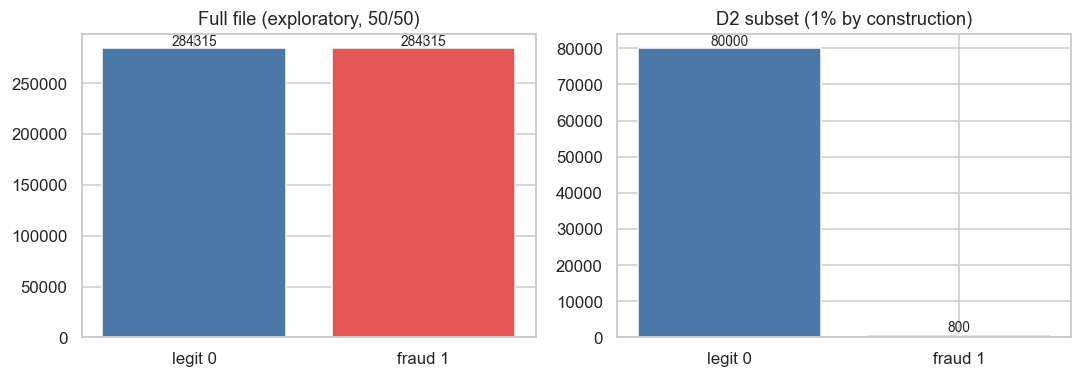

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, series, title in [
    (axes[0], df_full["Class"], "Full file (exploratory, 50/50)"),
    (axes[1], df["Class"], "D2 subset (1% by construction)"),
]:
    c = series.value_counts().sort_index()
    bars = ax.bar(["legit 0", "fraud 1"], c.values, color=["#4c78a8", "#e45756"])
    ax.bar_label(bars, fmt="%d", fontsize=9)
    ax.set_title(title)
plt.tight_layout(); plt.show()


### Split before model-guided exploration

Create the stratified train/test split now. The held-out test set is reserved for final evaluation; feature-distribution plots, correlations, scaling, and DBSCAN fitting use training data only. This reduces information leakage from the test set into the modelling process.


In [5]:
df_train, df_test = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["Class"], random_state=SEED
)
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
X_train = df_train[feature_cols].to_numpy()
X_test = df_test[feature_cols].to_numpy()
y_train = df_train["Class"].to_numpy()
y_test = df_test["Class"].to_numpy()
print(f"train {len(y_train):,} fraud={y_train.sum()} | test {len(y_test):,} fraud={y_test.sum()}")


train 64,640 fraud=640 | test 16,160 fraud=160


**Why this step:** Class-conditional distributions and univariate AUCs provide a quick check for potentially informative features. These are exploratory summaries—not proof that a feature will improve a multivariate classifier.



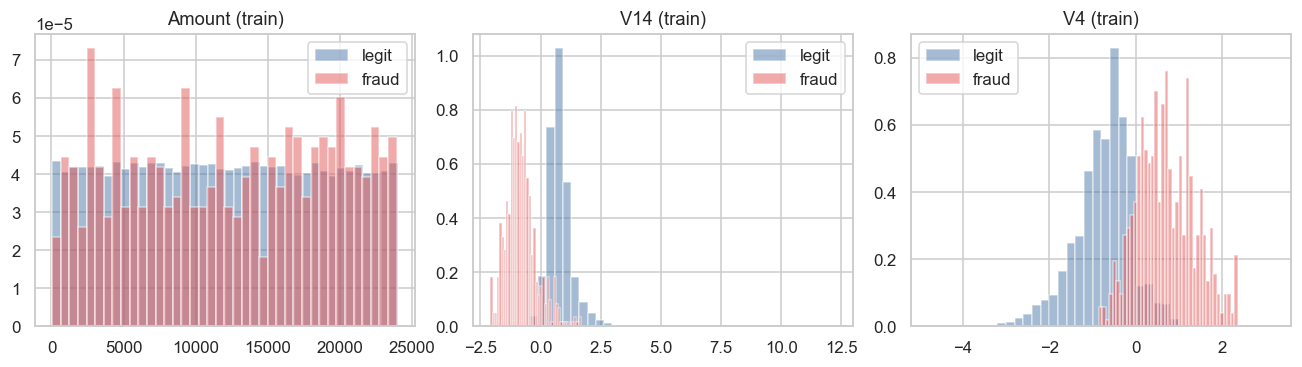

train Amount median legit/fraud: 11953.93 12262.15
top univariate AUC (train):
 feature      auc
    V14 0.967344
     V4 0.948683
    V12 0.948479
    V11 0.941158
    V10 0.927712
     V3 0.921945


In [6]:
# Train-only amount and a few class-conditional features
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for cls, color, lab in [(0, "#4c78a8", "legit"), (1, "#e45756", "fraud")]:
    axes[0].hist(df_train.loc[df_train.Class == cls, "Amount"], bins=40, density=True,
                 alpha=0.5, color=color, label=lab)
axes[0].set_title("Amount (train)"); axes[0].legend()

auc_rows = []
for col in feature_cols:
    x = df_train[col].to_numpy()
    y = y_train
    # direction-invariant univariate AUC
    a = roc_auc_score(y, x)
    auc_rows.append((col, max(a, 1 - a)))
auc_rank = pd.DataFrame(auc_rows, columns=["feature", "auc"]).sort_values("auc", ascending=False)
for ax, col in zip(axes[1:], auc_rank.feature.head(2)):
    for cls, color, lab in [(0, "#4c78a8", "legit"), (1, "#e45756", "fraud")]:
        ax.hist(df_train.loc[df_train.Class == cls, col], bins=40, density=True,
                alpha=0.5, color=color, label=lab)
    ax.set_title(f"{col} (train)"); ax.legend()
plt.tight_layout(); plt.show()

print("train Amount median legit/fraud:",
      float(df_train.loc[df_train.Class == 0, "Amount"].median()),
      float(df_train.loc[df_train.Class == 1, "Amount"].median()))
print("top univariate AUC (train):\n", auc_rank.head(6).to_string(index=False))


**Why this step:** Target correlations and feature-to-feature correlations summarize linear associations and redundancy in the training data. They do not establish that DBSCAN is appropriate; the clustering experiment is evaluated separately.



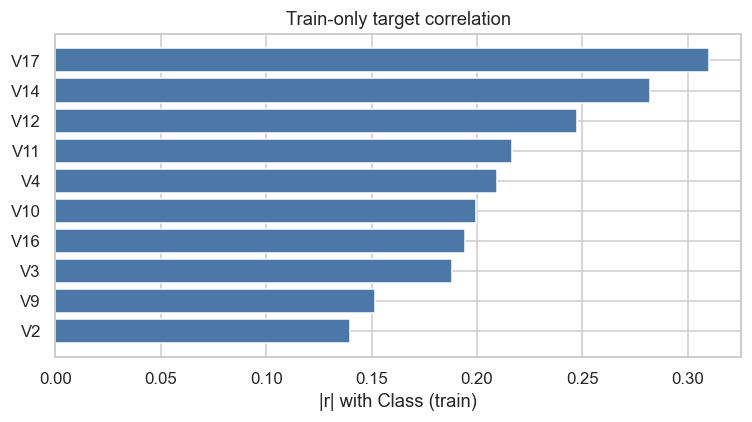

top |r| with Class: [('V17', 0.309927238248244), ('V14', 0.2821299584036519), ('V12', 0.2473969230243835)]
largest feature–feature |r| (train): 0.605 (V27, V7)
These ranks describe linear association on train; they do not prove a clustering architecture.


In [7]:
corr_y = df_train[feature_cols].corrwith(df_train["Class"]).abs().sort_values(ascending=False)
cm = df_train[feature_cols].corr().abs()
off = cm.where(~np.eye(len(cm), dtype=bool))
pair_b = off.max().idxmax()
pair_a = off[pair_b].idxmax()

fig, ax = plt.subplots(figsize=(7, 4))
top = corr_y.head(10)
ax.barh(top.index[::-1], top.values[::-1], color="#4c78a8")
ax.set_xlabel("|r| with Class (train)")
ax.set_title("Train-only target correlation")
plt.tight_layout(); plt.show()

print("top |r| with Class:", list(top.head(3).items()))
print(f"largest feature–feature |r| (train): {float(off.max().max()):.3f} ({pair_a}, {pair_b})")
print("These ranks describe linear association on train; they do not prove a clustering architecture.")


## 4. Scale using training data only

Standardization is important for distance-based methods because feature scales affect distances. The scaler is fitted on `X_train` and then applied unchanged to `X_test`; fitting it on both sets would leak test-set distribution information. Tree-based models are evaluated on the raw numeric features.


**Output check:** Confirm that train and test matrices have the expected shapes. The key methodological point is that the scaler learns parameters from training observations only.



In [8]:
scaler = StandardScaler()
Z_train = scaler.fit_transform(X_train)
Z_test = scaler.transform(X_test)
print("scaler fit on train. Z_train", Z_train.shape, "Z_test", Z_test.shape)


scaler fit on train. Z_train (64640, 29) Z_test (16160, 29)


## 5. DBSCAN feature construction

DBSCAN does not provide a standard `predict()` method for unseen observations. Here, test points inherit the nearest training point's cluster label, unless the nearest-neighbour distance exceeds `eps`, in which case they are marked as noise (`-1`). This is an explicit approximation for out-of-sample assignment, not native DBSCAN prediction.

Two representations are compared:

- **Paper-style numeric IDs:** append integer cluster labels, iterating the DBSCAN augmentation. This preserves the paper-style idea for comparison, but cluster IDs are arbitrary category labels and their numeric magnitudes have no intrinsic meaning.
- **Binary noise flag:** append only `is_noise = 1` for DBSCAN noise and `0` otherwise. This avoids treating cluster identifiers as ordered numerical values and is the cleaner representation tested here.

The helper cell defines these transformations; the next cell reports cluster/noise diagnostics and constructs the augmented feature matrices.


In [9]:
def assign_out_of_sample(Z_train, labels_train, Z_query, eps=EPS):
    nn = NearestNeighbors(n_neighbors=1, n_jobs=-1)
    nn.fit(Z_train)
    dist, idx = nn.kneighbors(Z_query, return_distance=True)
    dist = dist[:, 0]
    labels = labels_train[idx[:, 0]].copy()
    far = dist > eps
    labels[far] = -1
    info = {"coverage": float((~far).mean()), "n_unassigned": int(far.sum()),
            "median_nn_dist": float(np.median(dist))}
    return labels, info


def paper_numeric_ids(Z_tr, Z_te, n_iter=PAPER_DBSCAN_ITERS, eps=EPS, min_samples=MIN_SAMPLES):
    # Iterative integer cluster IDs (paper-style encoding).
    tr, te = np.array(Z_tr, float), np.array(Z_te, float)
    history = []
    for i in range(n_iter):
        lab_tr = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(tr)
        lab_te, meta = assign_out_of_sample(tr, lab_tr, te, eps=eps)
        history.append({
            "iteration": i + 1,
            "n_clusters": int(len(set(lab_tr) - {-1})),
            "train_noise": int((lab_tr == -1).sum()),
            **meta,
        })
        tr = np.column_stack([tr, lab_tr.astype(float)])
        te = np.column_stack([te, lab_te.astype(float)])
    return tr, te, history


def noise_flag(Z_tr, Z_te, eps=EPS, min_samples=MIN_SAMPLES):
    # Binary is_noise from a single DBSCAN on scaled train features.
    lab_tr = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(Z_tr)
    lab_te, meta = assign_out_of_sample(Z_tr, lab_tr, Z_te, eps=eps)
    flag_tr = (lab_tr == -1).astype(float)[:, None]
    flag_te = (lab_te == -1).astype(float)[:, None]
    meta.update({
        "n_clusters": int(len(set(lab_tr) - {-1})),
        "labels_train": lab_tr,
        "labels_test": lab_te,
    })
    return flag_tr, flag_te, meta


**How to read these diagnostics:** Cluster count and noise rates show how DBSCAN partitions the training data and how the nearest-neighbour rule assigns test points. The fraud rate among noise points is descriptive only; it is not evidence of out-of-sample predictive improvement by itself.



In [10]:
print("Paper-style numeric IDs (train-only fit, paper encoding)...")
Z_train_paper, Z_test_paper, paper_hist = paper_numeric_ids(Z_train, Z_test)
print(pd.DataFrame(paper_hist).to_string(index=False))

print("\nLeakage-safe noise flag...")
flag_tr, flag_te, noise_meta = noise_flag(Z_train, Z_test)
print({k: noise_meta[k] for k in ["n_clusters", "coverage", "n_unassigned", "median_nn_dist"]})

lab_tr, lab_te = noise_meta["labels_train"], noise_meta["labels_test"]

def class_noise_rates(labels, y):
    noise = labels == -1
    return {
        "fraud_marked_noise": float(noise[y == 1].mean()),
        "legit_marked_noise": float(noise[y == 0].mean()),
        "P(fraud | noise)": float(y[noise].mean()) if noise.any() else np.nan,
        "n_noise": int(noise.sum()),
        "n_clusters_occupied_by_fraud": int(pd.Series(labels[(y == 1) & (labels >= 0)]).nunique()),
    }

print("train", class_noise_rates(lab_tr, y_train))
print("test ", class_noise_rates(lab_te, y_test))

# cluster-level fraud rate on TRAIN (for EDA, not a performance claim)
train_cl = pd.DataFrame({"cluster": lab_tr, "fraud": y_train})
summary = train_cl.groupby("cluster").agg(n=("fraud", "size"), fraud_rate=("fraud", "mean")).sort_values("n", ascending=False)
print("\ntrain cluster sizes / fraud rate (cluster -1 = noise):")
print(summary.head(8).to_string())

X_train_flag = np.column_stack([X_train, flag_tr])  # trees
X_test_flag = np.column_stack([X_test, flag_te])
Z_train_flag = np.column_stack([Z_train, flag_tr])  # LR / KNN / SVM
Z_test_flag = np.column_stack([Z_test, flag_te])


Paper-style numeric IDs (train-only fit, paper encoding)...
 iteration  n_clusters  train_noise  coverage  n_unassigned  median_nn_dist
         1         380        20705  0.747463          4081         1.30147
         2         360        20766  0.747463          4081         1.30147

Leakage-safe noise flag...
{'n_clusters': 380, 'coverage': 0.7474628712871287, 'n_unassigned': 4081, 'median_nn_dist': 1.3014697852998505}
train {'fraud_marked_noise': 0.6421875, 'legit_marked_noise': 0.31709375, 'P(fraud | noise)': 0.0198502777106979, 'n_noise': 20705, 'n_clusters_occupied_by_fraud': 34}
test  {'fraud_marked_noise': 0.7375, 'legit_marked_noise': 0.3289375, 'P(fraud | noise)': 0.021929009477792232, 'n_noise': 5381, 'n_clusters_occupied_by_fraud': 20}

train cluster sizes / fraud rate (cluster -1 = noise):
             n  fraud_rate
cluster                   
 1       27460    0.001092
-1       20705    0.019850
 23       2790    0.000000
 6        2711    0.000000
 5        1849    0.0

## 6. Fit and evaluate models

All variants use the same train/test split to make comparisons more meaningful. The paper-style group contains Random Forest (`n_estimators=3`), KNN (`k=3`), and RBF SVM, plus majority and disjunctive OR voting. The broader baselines include Logistic Regression, a 200-tree Random Forest, XGBoost, and CatBoost when available.

**Metrics:** precision, recall, F1, MCC, false positives (FP), and false negatives (FN) describe classification decisions. PR-AUC and ROC-AUC use probability or decision scores and assess ranking quality; SVM decision scores are not probabilities. Accuracy is included for completeness but is not the primary criterion under class imbalance.


In [11]:
def evaluate(name, y_true, y_pred, y_score=None, threshold=THRESHOLD):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    row = {
        "model": name,
        "threshold": threshold if y_score is not None else "native predict",
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "accuracy": accuracy_score(y_true, y_pred),
        "pr_auc": np.nan,
        "roc_auc": np.nan,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }
    if y_score is not None:
        row["pr_auc"] = average_precision_score(y_true, y_score)
        row["roc_auc"] = roc_auc_score(y_true, y_score)
    print(f"{name:<44}  P={row['precision']:.3f} R={row['recall']:.3f} F1={row['f1']:.3f}  "
          f"PR-AUC={row['pr_auc'] if pd.notna(row['pr_auc']) else float('nan'):.3f}  FP={row['fp']} FN={row['fn']}")
    return row


def run_clf(name, clf, Xtr, Xte, score="proba"):
    print(f"fitting {name} on {Xtr.shape} ...", flush=True)
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    if score == "proba":
        sc = clf.predict_proba(Xte)[:, 1]
    elif score == "decision":
        sc = clf.decision_function(Xte)
    else:
        sc = None
    results.append(evaluate(name, y_test, pred, sc,
                            threshold=THRESHOLD if score == "proba" else "native predict"))
    return pred


def paper_models():
    rf = RandomForestClassifier(n_estimators=3, max_depth=None, random_state=SEED, n_jobs=-1)
    knn = KNeighborsClassifier(n_neighbors=3, n_jobs=-1)
    svm = SVC(kernel="rbf", C=1.0, random_state=SEED, cache_size=1000)
    return rf, knn, svm


def votes(rf_p, knn_p, svm_p, tag):
    maj = ((rf_p + knn_p + svm_p) >= 2).astype(int)
    dve = ((rf_p + knn_p + svm_p) >= 1).astype(int)
    results.append(evaluate(f"majority vote {tag}", y_test, maj, y_score=None))
    results.append(evaluate(f"disjunctive OR {tag}", y_test, dve, y_score=None))
    return maj, dve


results = []
preds = {}
pos_w = (y_train == 0).sum() / max((y_train == 1).sum(), 1)


### 6.1 Paper-style experiment: original features vs. numeric DBSCAN IDs

This comparison keeps the paper's RF/KNN/SVM and voting setup, then tests it with and without the iterative numeric cluster-ID features. The goal is to measure the effect of that representation—not to claim an exact reproduction of the paper's unpublished implementation.


**Interpretation:** This is the paper-style comparison. The numeric-ID representation is intentionally retained as a baseline, even though cluster IDs have no natural numerical order. Compare each classifier with its own original-feature version.



In [12]:
# Trees stay on raw Amount/V* columns; KNN/SVM stay on scaled columns.
id_tr = Z_train_paper[:, Z_train.shape[1]:]
id_te = Z_test_paper[:, Z_train.shape[1]:]
X_train_paper_ids = np.column_stack([X_train, id_tr])
X_test_paper_ids = np.column_stack([X_test, id_te])

print("=== Paper classifiers on original features ===")
rf, knn, svm = paper_models()
p_rf = run_clf("RF paper n=3 | original", rf, X_train, X_test)
p_knn = run_clf("KNN k=3 | original", knn, Z_train, Z_test)
p_svm = run_clf("SVM RBF | original", svm, Z_train, Z_test, score="decision")
preds["maj_orig"], preds["dve_orig"] = votes(p_rf, p_knn, p_svm, "| original")

print("\n=== Paper-style numeric cluster IDs (not the clean encoding) ===")
rf, knn, svm = paper_models()
q_rf = run_clf("RF paper n=3 | numeric IDs", rf, X_train_paper_ids, X_test_paper_ids)
q_knn = run_clf("KNN k=3 | numeric IDs", knn, Z_train_paper, Z_test_paper)
q_svm = run_clf("SVM RBF | numeric IDs", svm, Z_train_paper, Z_test_paper, score="decision")
preds["maj_ids"], preds["dve_ids"] = votes(q_rf, q_knn, q_svm, "| numeric IDs")


=== Paper classifiers on original features ===
fitting RF paper n=3 | original on (64640, 29) ...
RF paper n=3 | original                       P=0.971 R=0.850 F1=0.907  PR-AUC=0.858  FP=4 FN=24
fitting KNN k=3 | original on (64640, 29) ...
KNN k=3 | original                            P=0.935 R=0.894 F1=0.914  PR-AUC=0.898  FP=10 FN=17
fitting SVM RBF | original on (64640, 29) ...
SVM RBF | original                            P=0.966 R=0.875 F1=0.918  PR-AUC=0.958  FP=5 FN=20
majority vote | original                      P=0.972 R=0.881 F1=0.925  PR-AUC=nan  FP=4 FN=19
disjunctive OR | original                     P=0.924 R=0.906 F1=0.915  PR-AUC=nan  FP=12 FN=15

=== Paper-style numeric cluster IDs (not the clean encoding) ===
fitting RF paper n=3 | numeric IDs on (64640, 31) ...
RF paper n=3 | numeric IDs                    P=0.952 R=0.863 F1=0.905  PR-AUC=0.867  FP=7 FN=22
fitting KNN k=3 | numeric IDs on (64640, 31) ...
KNN k=3 | numeric IDs                         P=0.942 R=0.906

### 6.2 Leakage-safe experiment: original features vs. noise flag

Each classifier is evaluated on its original features and on the same features plus a single DBSCAN noise indicator. This paired comparison isolates whether the extra anomaly signal helps. The larger Random Forest and gradient-boosting models provide stronger non-paper baselines.


**Interpretation:** These are paired tests of the same model family on the original features and on the original features plus `is_noise`. A small change may be due to this particular split; use the held-out metrics and confusion counts together.



In [13]:
print("=== Same classifiers, original vs + noise flag ===")
run_clf("LogReg | original", LogisticRegression(class_weight="balanced", max_iter=500, random_state=SEED),
        Z_train, Z_test)
run_clf("LogReg | + noise flag", LogisticRegression(class_weight="balanced", max_iter=500, random_state=SEED),
        Z_train_flag, Z_test_flag)

rf_kw = dict(n_estimators=200, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
run_clf("RF n=200 | original", RandomForestClassifier(**rf_kw), X_train, X_test)
run_clf("RF n=200 | + noise flag", RandomForestClassifier(**rf_kw), X_train_flag, X_test_flag)

xgb_kw = dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
              colsample_bytree=0.8, scale_pos_weight=pos_w, random_state=SEED,
              eval_metric="aucpr", n_jobs=4, tree_method="hist")
run_clf("XGBoost | original", XGBClassifier(**xgb_kw), X_train, X_test)
preds["xgb"] = run_clf("XGBoost | + noise flag", XGBClassifier(**xgb_kw), X_train_flag, X_test_flag)

if CatBoostClassifier is None:
    print("CatBoost skipped (package not installed).")
else:
    cb_kw = dict(iterations=200, depth=6, learning_rate=0.08, auto_class_weights="Balanced",
                 random_seed=SEED, verbose=False, allow_writing_files=False, thread_count=4)
    try:
        run_clf("CatBoost | original", CatBoostClassifier(**cb_kw), X_train, X_test)
        run_clf("CatBoost | + noise flag", CatBoostClassifier(**cb_kw), X_train_flag, X_test_flag)
    except Exception as exc:
        print(f"CatBoost failed ({type(exc).__name__}: {exc}). Continuing without CatBoost rows.")

# paper trio on the clean flag (for an apples-to-apples DVE vs original DVE)
print("\n=== Paper trio + leakage-safe noise flag ===")
rf, knn, svm = paper_models()
r_rf = run_clf("RF paper n=3 | + noise flag", rf, X_train_flag, X_test_flag)
r_knn = run_clf("KNN k=3 | + noise flag", knn, Z_train_flag, Z_test_flag)
r_svm = run_clf("SVM RBF | + noise flag", svm, Z_train_flag, Z_test_flag, score="decision")
preds["maj_flag"], preds["dve_flag"] = votes(r_rf, r_knn, r_svm, "| + noise flag")


=== Same classifiers, original vs + noise flag ===
fitting LogReg | original on (64640, 29) ...
LogReg | original                             P=0.288 R=0.956 F1=0.442  PR-AUC=0.902  FP=379 FN=7
fitting LogReg | + noise flag on (64640, 30) ...
LogReg | + noise flag                         P=0.282 R=0.956 F1=0.435  PR-AUC=0.900  FP=390 FN=7
fitting RF n=200 | original on (64640, 29) ...
RF n=200 | original                           P=0.979 R=0.856 F1=0.913  PR-AUC=0.959  FP=3 FN=23
fitting RF n=200 | + noise flag on (64640, 30) ...
RF n=200 | + noise flag                       P=0.972 R=0.863 F1=0.914  PR-AUC=0.959  FP=4 FN=22
fitting XGBoost | original on (64640, 29) ...
XGBoost | original                            P=0.900 R=0.900 F1=0.900  PR-AUC=0.955  FP=16 FN=16
fitting XGBoost | + noise flag on (64640, 30) ...
XGBoost | + noise flag                        P=0.901 R=0.906 F1=0.903  PR-AUC=0.955  FP=16 FN=15
fitting CatBoost | original on (64640, 29) ...
CatBoost | original         

## 7. Results

The following figures summarize the experimental design, compare the paper-style ensemble with stronger baselines, and show classification errors. Read them together: a model can have a higher recall while also generating more false alarms, so no single metric is sufficient.


In [35]:
# Ensures linter knows 'tbl' exists
if "tbl" not in globals():
  tbl = pd.DataFrame(results)


### Experiment map

This diagram summarizes the experiment branches and model families. It is a schematic of the notebook's design rather than a learned decision tree; the actual performance comparison follows in the next figures.



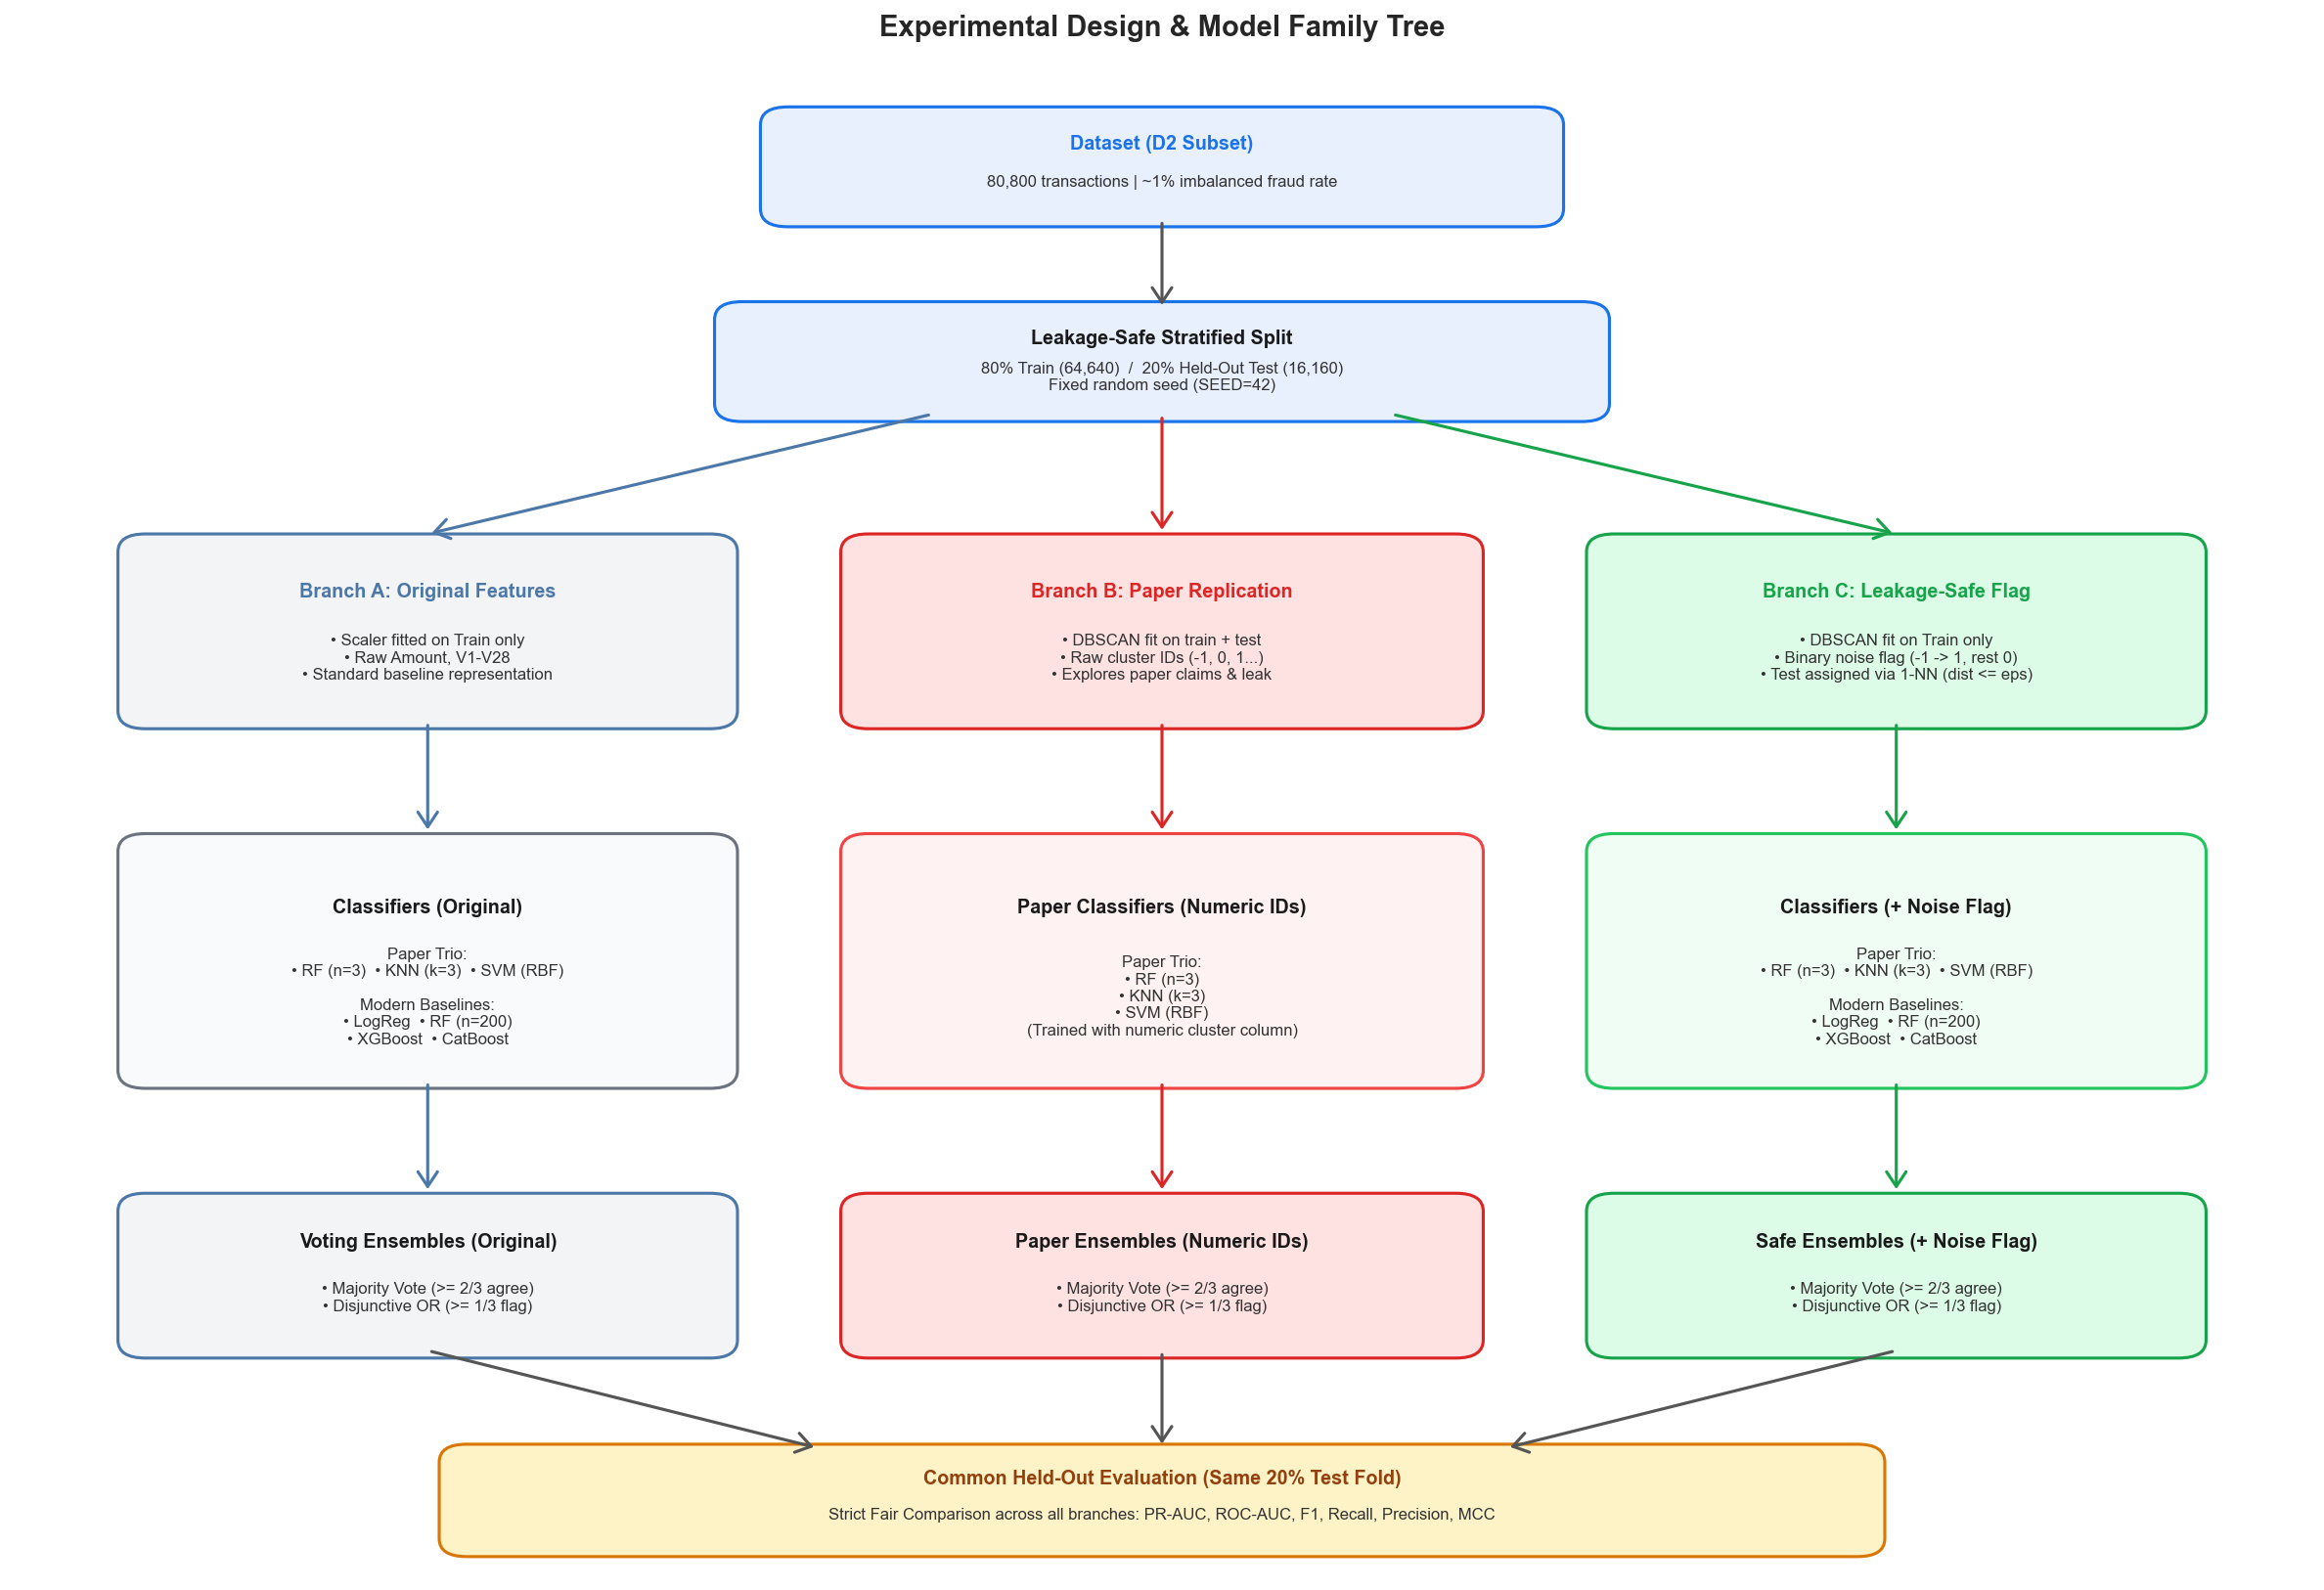

In [25]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# Canvas setup
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(16, 11), dpi=150)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")


def draw_node(
    x, y, w, h, title, body, facecolor, edgecolor, title_color="#1a1a1a"
):
    """Draw a styled rounded card with header and bullet points."""
    box = patches.FancyBboxPatch(
        (x - w / 2, y - h / 2),
        w,
        h,
        boxstyle="round,pad=0.5,rounding_size=1.2",
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=1.5,
    )
    ax.add_patch(box)
    ax.text(
        x,
        y + h * 0.22,
        title,
        ha="center",
        va="center",
        fontweight="bold",
        fontsize=9.5,
        color=title_color,
    )
    ax.text(
        x,
        y - h * 0.15,
        body,
        ha="center",
        va="center",
        fontsize=8,
        color="#333333",
        multialignment="center",
    )


def draw_arrow(x1, y1, x2, y2, color="#555555"):
    """Draw a connecting directional arrow."""
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->,head_width=0.4,head_length=0.6",
            color=color,
            lw=1.5,
            shrinkA=2,
            shrinkB=2,
        ),
    )


# -------------------------------------------------------------------------
# 1. Dataset & Split Nodes
# -------------------------------------------------------------------------
draw_node(
    50,
    94,
    34,
    7,
    "Dataset (D2 Subset)",
    "80,800 transactions | ~1% imbalanced fraud rate",
    "#E8F0FE",
    "#1A73E8",
    "#1A73E8",
)

draw_node(
    50,
    81,
    38,
    7,
    "Leakage-Safe Stratified Split",
    "80% Train (64,640)  /  20% Held-Out Test (16,160)\nFixed random seed (SEED=42)",
    "#E8F0FE",
    "#1A73E8",
)
draw_arrow(50, 90.5, 50, 84.5)

# Branching arrows from split
draw_arrow(40, 77.5, 18, 69.5, "#4C78A8")
draw_arrow(50, 77.5, 50, 69.5, "#DC2626")
draw_arrow(60, 77.5, 82, 69.5, "#16A34A")

# -------------------------------------------------------------------------
# 2. Experimental Branches (Feature Spaces)
# -------------------------------------------------------------------------
draw_node(
    18,
    63,
    26,
    12,
    "Branch A: Original Features",
    "• Scaler fitted on Train only\n• Raw Amount, V1-V28\n• Standard baseline representation",
    "#F3F4F6",
    "#4C78A8",
    "#4C78A8",
)
draw_node(
    50,
    63,
    27,
    12,
    "Branch B: Paper Replication",
    "• DBSCAN fit on train + test\n• Raw cluster IDs (-1, 0, 1...)\n• Explores paper claims & leak",
    "#FEE2E2",
    "#DC2626",
    "#DC2626",
)
draw_node(
    82,
    63,
    26,
    12,
    "Branch C: Leakage-Safe Flag",
    "• DBSCAN fit on Train only\n• Binary noise flag (-1 -> 1, rest 0)\n• Test assigned via 1-NN (dist <= eps)",
    "#DCFCE7",
    "#16A34A",
    "#16A34A",
)

draw_arrow(18, 57, 18, 49.5, "#4C78A8")
draw_arrow(50, 57, 50, 49.5, "#DC2626")
draw_arrow(82, 57, 82, 49.5, "#16A34A")

# -------------------------------------------------------------------------
# 3. Classifiers
# -------------------------------------------------------------------------
draw_node(
    18,
    41,
    26,
    16,
    "Classifiers (Original)",
    "Paper Trio:\n• RF (n=3)  • KNN (k=3)  • SVM (RBF)\n\nModern Baselines:\n• LogReg  • RF (n=200)\n• XGBoost  • CatBoost",
    "#F9FAFB",
    "#6B7280",
)
draw_node(
    50,
    41,
    27,
    16,
    "Paper Classifiers (Numeric IDs)",
    "Paper Trio:\n• RF (n=3)\n• KNN (k=3)\n• SVM (RBF)\n(Trained with numeric cluster column)",
    "#FEF2F2",
    "#EF4444",
)
draw_node(
    82,
    41,
    26,
    16,
    "Classifiers (+ Noise Flag)",
    "Paper Trio:\n• RF (n=3)  • KNN (k=3)  • SVM (RBF)\n\nModern Baselines:\n• LogReg  • RF (n=200)\n• XGBoost  • CatBoost",
    "#F0FDF4",
    "#22C55E",
)

draw_arrow(18, 33, 18, 25.5, "#4C78A8")
draw_arrow(50, 33, 50, 25.5, "#DC2626")
draw_arrow(82, 33, 82, 25.5, "#16A34A")

# -------------------------------------------------------------------------
# 4. Ensembles
# -------------------------------------------------------------------------
draw_node(
    18,
    20,
    26,
    10,
    "Voting Ensembles (Original)",
    "• Majority Vote (>= 2/3 agree)\n• Disjunctive OR (>= 1/3 flag)",
    "#F3F4F6",
    "#4C78A8",
)
draw_node(
    50,
    20,
    27,
    10,
    "Paper Ensembles (Numeric IDs)",
    "• Majority Vote (>= 2/3 agree)\n• Disjunctive OR (>= 1/3 flag)",
    "#FEE2E2",
    "#DC2626",
)
draw_node(
    82,
    20,
    26,
    10,
    "Safe Ensembles (+ Noise Flag)",
    "• Majority Vote (>= 2/3 agree)\n• Disjunctive OR (>= 1/3 flag)",
    "#DCFCE7",
    "#16A34A",
)

# Arrows into unified evaluation
draw_arrow(18, 15, 35, 8.5, "#555555")
draw_arrow(50, 15, 50, 8.5, "#555555")
draw_arrow(82, 15, 65, 8.5, "#555555")

# -------------------------------------------------------------------------
# 5. Common Held-Out Evaluation
# -------------------------------------------------------------------------
draw_node(
    50,
    5,
    62,
    6.5,
    "Common Held-Out Evaluation (Same 20% Test Fold)",
    "Strict Fair Comparison across all branches: PR-AUC, ROC-AUC, F1, Recall, Precision, MCC",
    "#FEF3C7",
    "#D97706",
    "#92400E",
)

plt.title(
    "Experimental Design & Model Family Tree",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.tight_layout()
plt.show()


### Paper-style ensemble vs. stronger baselines

The dashed vertical line is the notebook's paper-style disjunctive OR implementation with numeric cluster IDs. Bars to its right outperform that reference on the displayed metric; bars to the left underperform it. The reference is this notebook's result on the same holdout—not the paper's published headline score.



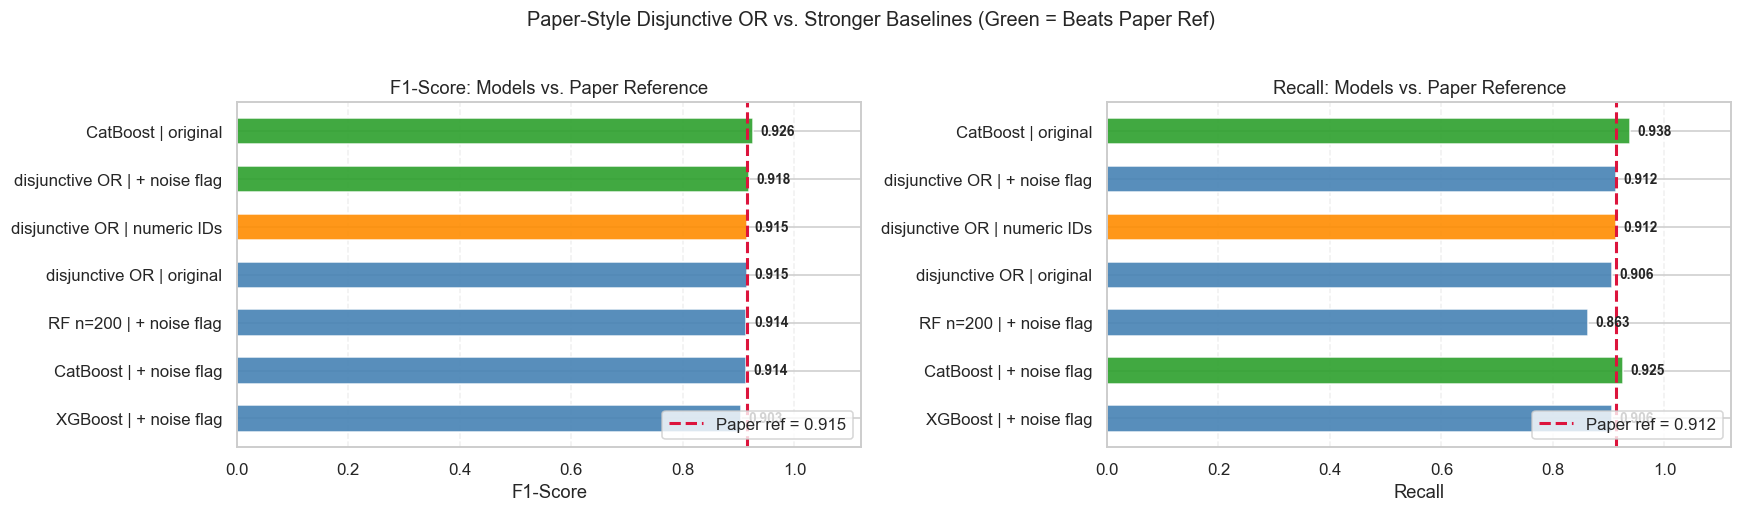

Paper reference: disjunctive OR | numeric IDs | F1 = 0.915 | Recall = 0.912


,model,accuracy,pr_auc,precision,recall,f1,mcc,fp,fn
0,XGBoost | + noise flag,0.998082,0.954984,0.900621,0.90625,0.903427,0.902462,16,15
1,CatBoost | + noise flag,0.998267,0.955937,0.902439,0.92500,0.913580,0.912776,16,12
2,RF n=200 | + noise flag,0.998391,0.958597,0.971831,0.86250,0.913907,0.914755,4,22
3,disjunctive OR | original,0.998329,NaN,0.923567,0.90625,0.914826,0.914025,12,15
4,disjunctive OR | numeric IDs,0.998329,NaN,0.918239,0.91250,0.915361,0.914521,13,14
5,disjunctive OR | + noise flag,0.998391,NaN,0.924051,0.91250,0.918239,0.917445,12,14
6,CatBoost | original,0.998515,0.957915,0.914634,0.93750,0.925926,0.925248,14,10


In [31]:
import matplotlib.pyplot as plt
import numpy as np, pandas as pd

ref_name = "disjunctive OR | numeric IDs"
paper_names = ["disjunctive OR | original", "disjunctive OR | + noise flag", ref_name]
baselines = ["CatBoost | original", "CatBoost | + noise flag", "XGBoost | + noise flag", "RF n=200 | + noise flag"]

selected_models = list(dict.fromkeys(paper_names + [m for m in baselines if m in tbl["model"].values]))
selected = tbl[tbl["model"].isin(selected_models)].sort_values("f1").reset_index(drop=True)
ref = tbl.loc[tbl["model"] == ref_name].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(16, max(4.5, 0.65 * len(selected))))

for ax, metric, label, ref_val in zip(axes, ["f1", "recall"], ["F1-Score", "Recall"], [ref["f1"], ref["recall"]]):
    bar_colors = ["darkorange" if m == ref_name else ("#2ca02c" if v > ref_val else "steelblue") for m, v in zip(selected["model"], selected[metric])]
    bars = ax.barh(selected["model"], selected[metric], height=0.55, color=bar_colors, alpha=0.9)
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9, fontweight="bold")
    ax.axvline(ref_val, color="crimson", ls="--", lw=2, label=f"Paper ref = {ref_val:.3f}")
    ax.set(xlim=(0, 1.12), xlabel=label, title=f"{label}: Models vs. Paper Reference")
    ax.grid(axis="x", ls="--", alpha=0.3)
    ax.legend(loc="lower right")

plt.suptitle("Paper-Style Disjunctive OR vs. Stronger Baselines (Green = Beats Paper Ref)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Paper reference: {ref_name} | F1 = {ref['f1']:.3f} | Recall = {ref['recall']:.3f}")
display(selected[["model", "accuracy", "pr_auc", "precision", "recall", "f1", "mcc", "fp", "fn"]])

### F1 and recall across evaluated models

F1 balances precision and recall, while recall measures the fraction of fraud cases detected. A higher recall can also mean more legitimate transactions are flagged, so interpret this figure alongside the confusion matrices and FP counts.



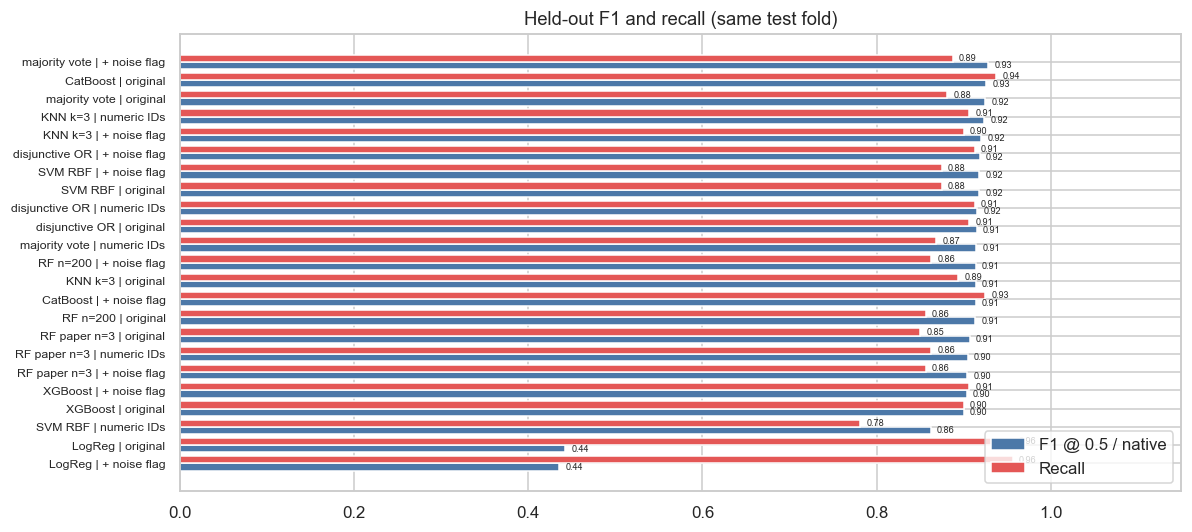

In [ ]:
plot_df = tbl.copy()
fig, ax = plt.subplots(figsize=(11, 5))
order = plot_df.sort_values("f1")
y = np.arange(len(order))

# 1. Capture the bar containers
b1 = ax.barh(y, order["f1"], color="#4c78a8", height=0.4, label="F1 @ 0.5 / native")
b2 = ax.barh(y + 0.4, order["recall"], color="#e45756", height=0.4, label="Recall")

# 2. Add value labels (change fmt to '%.3f' if you need 3 decimal places)
ax.bar_label(b1, fmt="%.2f", padding=4, fontsize=6)
ax.bar_label(b2, fmt="%.2f", padding=4, fontsize=6)

ax.set_yticks(y + 0.2)
ax.set_yticklabels(order["model"], fontsize=8)

# Slightly increased x-limit so labels are not cut off at the edge
ax.set_xlim(0, 1.15)

ax.legend(loc="lower right")
ax.set_title("Held-out F1 and recall (same test fold)")
plt.tight_layout()
plt.show()


### Confusion matrices: missed fraud vs. false alarms

Rows are actual classes and columns are predicted classes. The bottom-left cell is false negatives (missed fraud); the top-right cell is false positives (legitimate transactions flagged as fraud). These counts make the operational trade-off more concrete than accuracy alone.



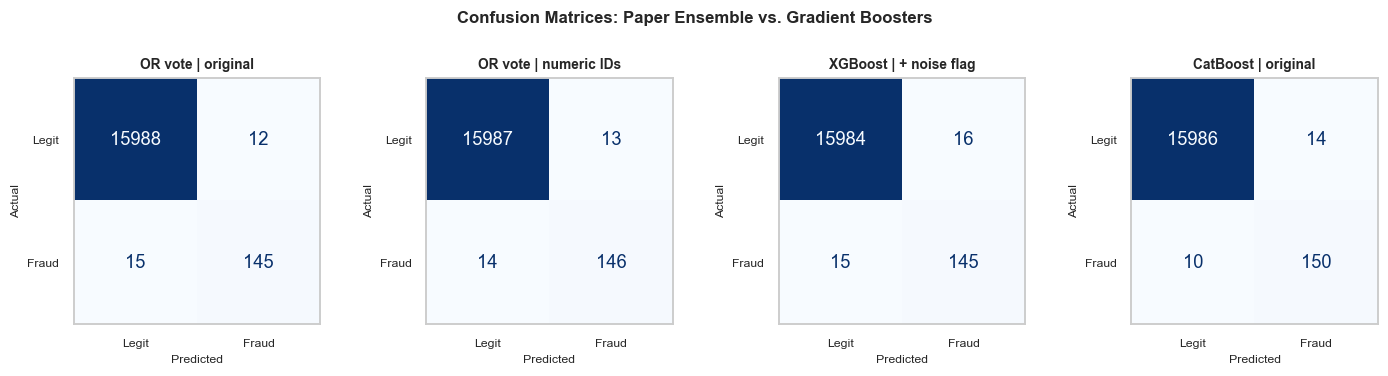

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
models_to_plot = [(axes[0], "dve_orig", "OR vote | original"), (axes[1], "dve_ids", "OR vote | numeric IDs"), (axes[2], "xgb", "XGBoost | + noise flag"), (axes[3], "CatBoost | original", "CatBoost | original")]

def get_cm(item):
    if item in preds:
        return confusion_matrix(y_test, preds[item], labels=[0, 1])
    m = tbl[tbl["model"] == item]
    return np.array([[m.iloc[0].tn, m.iloc[0].fp], [m.iloc[0].fn, m.iloc[0].tp]]) if not m.empty else None

for ax, key, title in models_to_plot:
    cm = get_cm(key)
    if cm is None:
        ax.set_visible(False)
        continue
    ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(title, fontsize=9, fontweight="bold")
    ax.set_xlabel("Predicted", fontsize=8)
    ax.set_ylabel("Actual", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.grid(False)

plt.suptitle("Confusion Matrices: Paper Ensemble vs. Gradient Boosters", fontsize=11, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8. Interpretation and discussion

Use these plots to answer the research questions. Focus on differences that matter for fraud detection—especially PR-AUC for scored classifiers, precision/recall/F1, MCC, and the FP/FN counts. Small gaps on one holdout split are suggestive, not proof of a reliable improvement.


### Effect of DBSCAN representation across model families

Each line tracks one feature representation across the paper-style classifiers and ensembles. Numeric cluster IDs and the noise flag encode different information, so changes are expected to vary by model. Compare both F1 and recall, and avoid over-interpreting small differences from a single split.



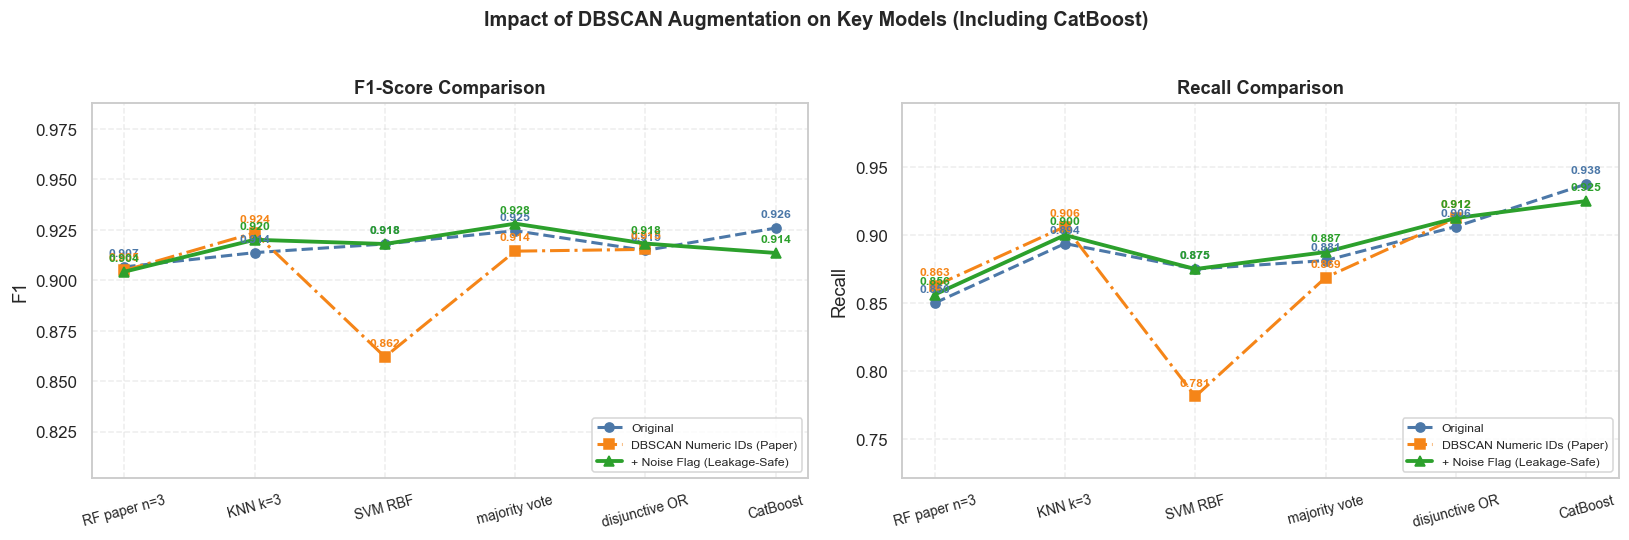

In [34]:
import matplotlib.pyplot as plt
import numpy as np, pandas as pd

models_to_plot = [
    "RF paper n=3",
    "KNN k=3",
    "SVM RBF",
    "majority vote",
    "disjunctive OR",
    "CatBoost",
]

variants = {
    "Original": "original",
    "DBSCAN Numeric IDs (Paper)": "numeric IDs",
    "+ Noise Flag (Leakage-Safe)": "+ noise flag",
}

styles = {
    "Original": {
        "color": "#4c78a8",
        "marker": "o",
        "ls": "--",
        "lw": 2,
        "markersize": 6,
    },
    "DBSCAN Numeric IDs (Paper)": {
        "color": "#f58518",
        "marker": "s",
        "ls": "-.",
        "lw": 2,
        "markersize": 6,
    },
    "+ Noise Flag (Leakage-Safe)": {
        "color": "#2ca02c",
        "marker": "^",
        "ls": "-",
        "lw": 2.5,
        "markersize": 7,
    },
}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
metrics = [("f1", "F1-Score Comparison"), ("recall", "Recall Comparison")]

for ax, (metric, title) in zip(axes, metrics):
  all_vals = []
  for v_label, v_suffix in variants.items():
    vals = [
        (
            tbl.loc[tbl["model"] == f"{m} | {v_suffix}", metric].iloc[0]
            if not tbl.loc[tbl["model"] == f"{m} | {v_suffix}"].empty
            else np.nan
        )
        for m in models_to_plot
    ]
    all_vals.extend([v for v in vals if pd.notna(v)])

    ax.plot(models_to_plot, vals, label=v_label, **styles[v_label])
    for i, val in enumerate(vals):
      if pd.notna(val):
        ax.annotate(
            f"{val:.3f}",
            (i, val),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8,
            fontweight="bold",
            color=styles[v_label]["color"],
        )

  ax.set_title(title, fontsize=12, fontweight="bold")
  ax.set_ylabel(metric.upper() if metric == "f1" else "Recall")
  ax.tick_params(axis="x", labelrotation=15, labelsize=9)
  ax.grid(True, ls="--", alpha=0.35)
  if all_vals:
    ax.set_ylim(max(0, min(all_vals) - 0.06), min(1.05, max(all_vals) + 0.06))
  ax.legend(loc="lower right", fontsize=8, frameon=True)

plt.suptitle(
    "Impact of DBSCAN Augmentation on Key Models (Including CatBoost)",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


## 9. Conclusions, limitations, and future work

### Main interpretation

- **DBSCAN noise flag:** If its scores are similar to or better than the original-feature model, this suggests a compact anomaly indicator can add useful information without imposing artificial distances between cluster IDs. The effect is model-dependent; DBSCAN does not guarantee an improvement.
- **Numeric cluster IDs:** These can help some models but hurt others because values such as cluster `3` and cluster `1` are not meaningfully ordered. Distance-based methods such as KNN and RBF SVM are particularly sensitive to this representation.
- **Why CatBoost may outperform the paper-style implementation:** CatBoost is a modern gradient-boosted tree method that builds trees sequentially to correct earlier errors and can learn nonlinear feature interactions. It also uses many boosting iterations (here, 200) rather than the paper-style Random Forest's three trees. That gives it substantially greater modelling capacity and can improve discrimination on tabular data. This is a plausible explanation, not proof that CatBoost is universally superior; the result depends on hyperparameters, sampling, threshold, and the held-out split. CatBoost's comparison should use the same test set and metrics, and its original-feature and noise-flag versions should be compared as a pair.
- **Paper comparison:** This notebook is a paper-style implementation, not an exact reproduction. In particular, the split and out-of-sample DBSCAN assignment are made leakage-safe, so the pipeline differs from the paper's described ordering.

### Limitations

- The 1% fraud prevalence is **constructed by sampling** from a balanced source dataset; real deployment prevalence and precision may differ.
- Only one stratified train/test split is evaluated, so uncertainty and run-to-run variation are unknown.
- The nearest-training-point rule is an approximation for assigning DBSCAN labels to unseen observations; it is not native DBSCAN inference.
- Numeric cluster IDs treat arbitrary labels as numeric values and should be interpreted as a reproduction-style baseline, not an ideal categorical encoding.
- The decision threshold is not tuned for a business cost function. Accuracy can be misleading, and high recall can come with excessive false positives.
- Model settings are not exhaustively tuned; compute time also limits the practicality of RBF SVM on this many observations.

### Future improvements

1. Repeat evaluation across multiple stratified seeds or use stratified cross-validation, reporting mean and standard deviation.
2. Tune decision thresholds using a validation set only, based on the desired FP/FN trade-off or expected fraud-review cost.
3. Compare PR-AUC and precision at a target recall, alongside MCC, F1, and confusion matrices.
4. Tune CatBoost/XGBoost and the larger Random Forest with a controlled validation procedure; keep the test set untouched.
5. Test categorical-safe cluster representations, such as one-hot cluster labels, and compare them with the binary noise flag.
6. Validate at a more realistic fraud prevalence or use a dataset with naturally observed class imbalance before making deployment claims.
